# 04_models：模型階梯、驗證、SHAP 與 conformal

設定與協定見 `setup.yaml`；程式在 `src/s04_models.py`。預設 `RUN = False` 只讀已存的結果。

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
R = ROOT / "results"
def show(name, n=60):
    p = R / f"{name}.csv"
    display(Markdown(f"**{name}**")); display(pd.read_csv(p, encoding="utf-8-sig").head(n)) if p.exists() else print("缺", name)
def fig(name, w=800):
    p = R / "figures" / name
    display(Image(filename=str(p), width=w)) if p.exists() else print("缺圖", name)

In [2]:
RUN = False
if RUN:
    from src import s04_models
    s04_models.main()

**04_ladder**

,模型,IC,lo,hi,t,p,ICIR,days,N_eff,folds,正 IC fold 比例
0,rule,-0.018564,-0.033835,-0.003293,-2.382604,1.719067e-02,-0.132869,3102.0,155.1,25.0,0.76
1,ridge,0.091013,0.067154,0.114872,7.476665,7.616130e-14,0.483741,3102.0,155.1,25.0,0.92
2,lgbm,0.106816,0.085697,0.127936,9.913104,0.000000e+00,0.624294,3102.0,155.1,25.0,1.00
3,ensemble,0.093692,0.071306,0.116078,8.203144,2.220446e-16,0.527755,3102.0,155.1,25.0,1.00


**04_paired**

,比較,ΔIC,lo,hi,p
0,ridge − rule,0.109577,0.083667,0.135487,2.220446e-16
1,lgbm − ridge,0.015803,0.000902,0.030705,3.765620e-02
2,lgbm − rule,0.125380,0.099731,0.151030,0.000000e+00
3,ensemble − lgbm,-0.013125,-0.024306,-0.001944,2.140755e-02
4,ensemble − ridge,0.002679,-0.002755,0.008113,3.339386e-01


**04_ridge_alpha**

,index,內部驗證 IC（fold 平均）,被選中次數
0,0.001,0.091953,NaN
1,0.010,0.091953,2.0
2,0.100,0.091953,NaN
3,1.000,0.091953,1.0
4,10.000,0.091954,3.0
5,100.000,0.091956,NaN
6,1000.000,0.091971,3.0
7,10000.000,0.092102,5.0
8,100000.000,0.091976,11.0


... (3 outputs left out)

,特徵,mean|SHAP|,方向（平均）,方向一致 fold 比例,排名標準差
0,vol60,0.030941,-0.926390,1.00,0.331662
1,near_high250,0.022415,0.757425,0.96,0.816497
2,volume_surge,0.014741,-0.637488,0.96,3.098118
3,overnight20,0.011283,-0.878359,1.00,2.325941
4,peer_tight,0.010228,-0.921332,1.00,1.993322
5,ret20,0.007203,-0.489354,0.92,3.303029
6,mkt_trend,0.006257,-0.237983,0.80,2.640707
7,adv60,0.006121,0.845834,1.00,2.573584
8,max_ret20,0.005926,-0.901402,1.00,2.278157
9,rev5,0.005853,-0.710471,0.96,3.261901


**04_conformal**

,fold,cov_ridge_80,width_ridge_80,cov_ridge_90,width_ridge_90,cov_lgbm_80,width_lgbm_80,cov_lgbm_90,width_lgbm_90,低於 80% 標記
0,1,0.803349,0.788307,0.903205,0.888461,0.805644,0.773691,0.895516,0.886673,False
1,2,0.799143,0.792766,0.900176,0.894829,0.788302,0.773478,0.886671,0.902741,True
2,3,0.800198,0.792464,0.904450,0.892681,0.806157,0.780165,0.903736,0.896479,False
3,4,0.790681,0.786792,0.889662,0.883408,0.784921,0.780537,0.887515,0.882977,True
4,5,0.803762,0.795466,0.902064,0.892879,0.803928,0.796814,0.903867,0.896113,False
5,6,0.802381,0.796627,0.901169,0.895679,0.801438,0.792090,0.902461,0.891938,False
6,7,0.798002,0.792073,0.900956,0.893118,0.802244,0.779694,0.898769,0.890138,False
7,8,0.789275,0.790357,0.887776,0.889511,0.789904,0.768732,0.891165,0.888042,True
8,9,0.806711,0.798622,0.910319,0.899485,0.810633,0.781171,0.904652,0.892658,False
9,10,0.800752,0.791058,0.899812,0.888783,0.789777,0.766341,0.895952,0.888941,True


{'deployed': 'lgbm', 'features': ['peer_ret20', 'peer_ret60', 'peer_gap20', 'leader_ret20', 'peer_tight', 'ret20', 'rev5', 'near_high250', 'vol60', 'max_ret20', 'overnight20', 'volume_surge', 'adv60', 'mkt_vol20', 'mkt_trend', 'disp20'], 'selection_rule': '在驗證期選「IC 的 NW CI 不含 0、且相對前一階的成對 ΔIC CI 不含 0」的最高一階； ΔIC 不顯著就保留較簡單的一階。集成只有在 ΔIC 相對最佳單一模型顯著時才部署。', 'overlay': '波動目標'}


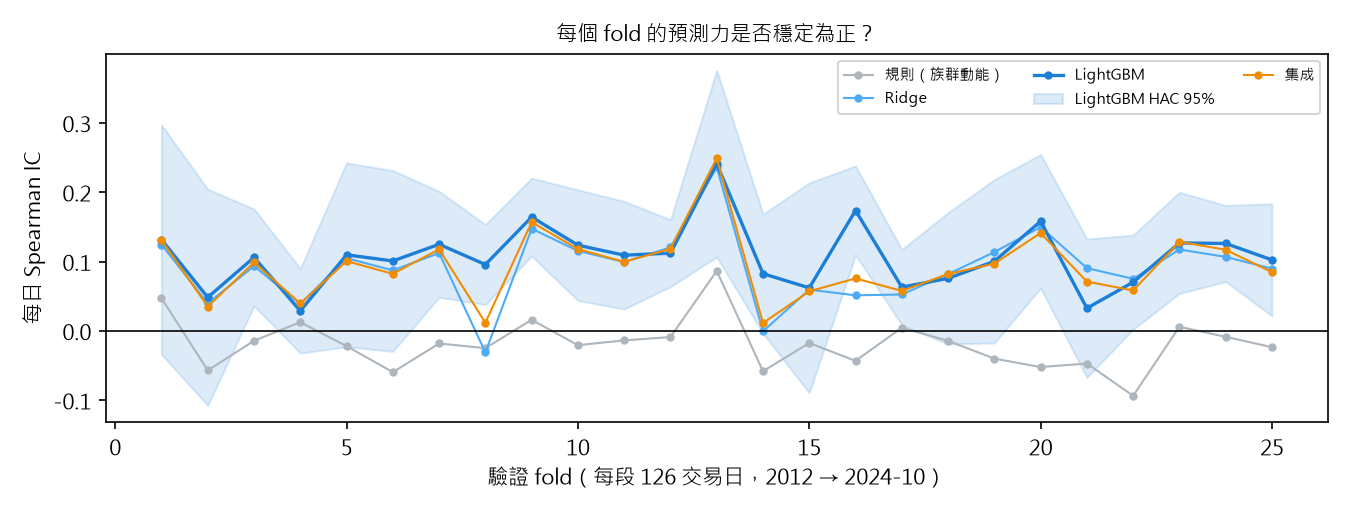

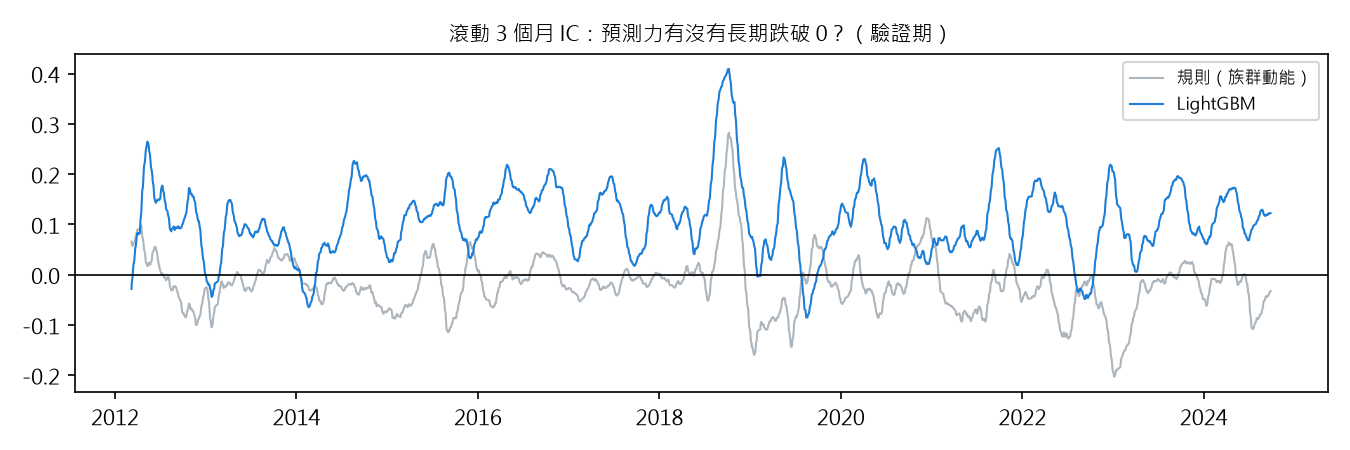

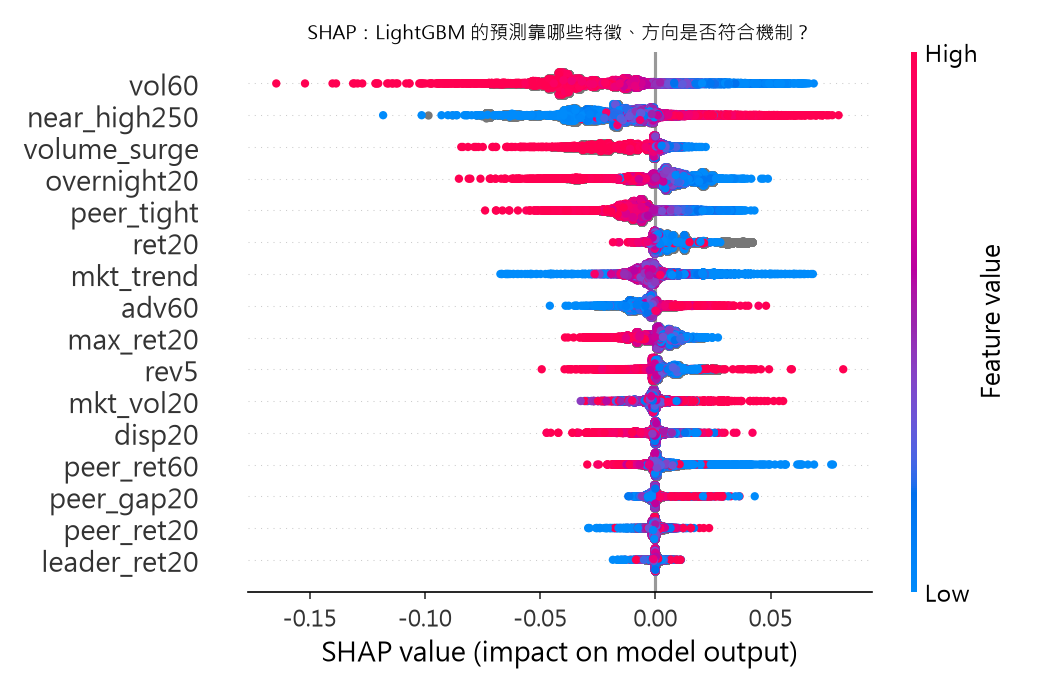

In [3]:
show("04_ladder"); show("04_paired"); show("04_ridge_alpha"); show("04_lgbm_grid"); show("04_shap"); show("04_conformal")
print(json.loads((R / "04_deployed.json").read_text(encoding="utf-8")))
fig("04_fold_ic.png"); fig("04_rolling_ic.png"); fig("04_shap.png", 650)